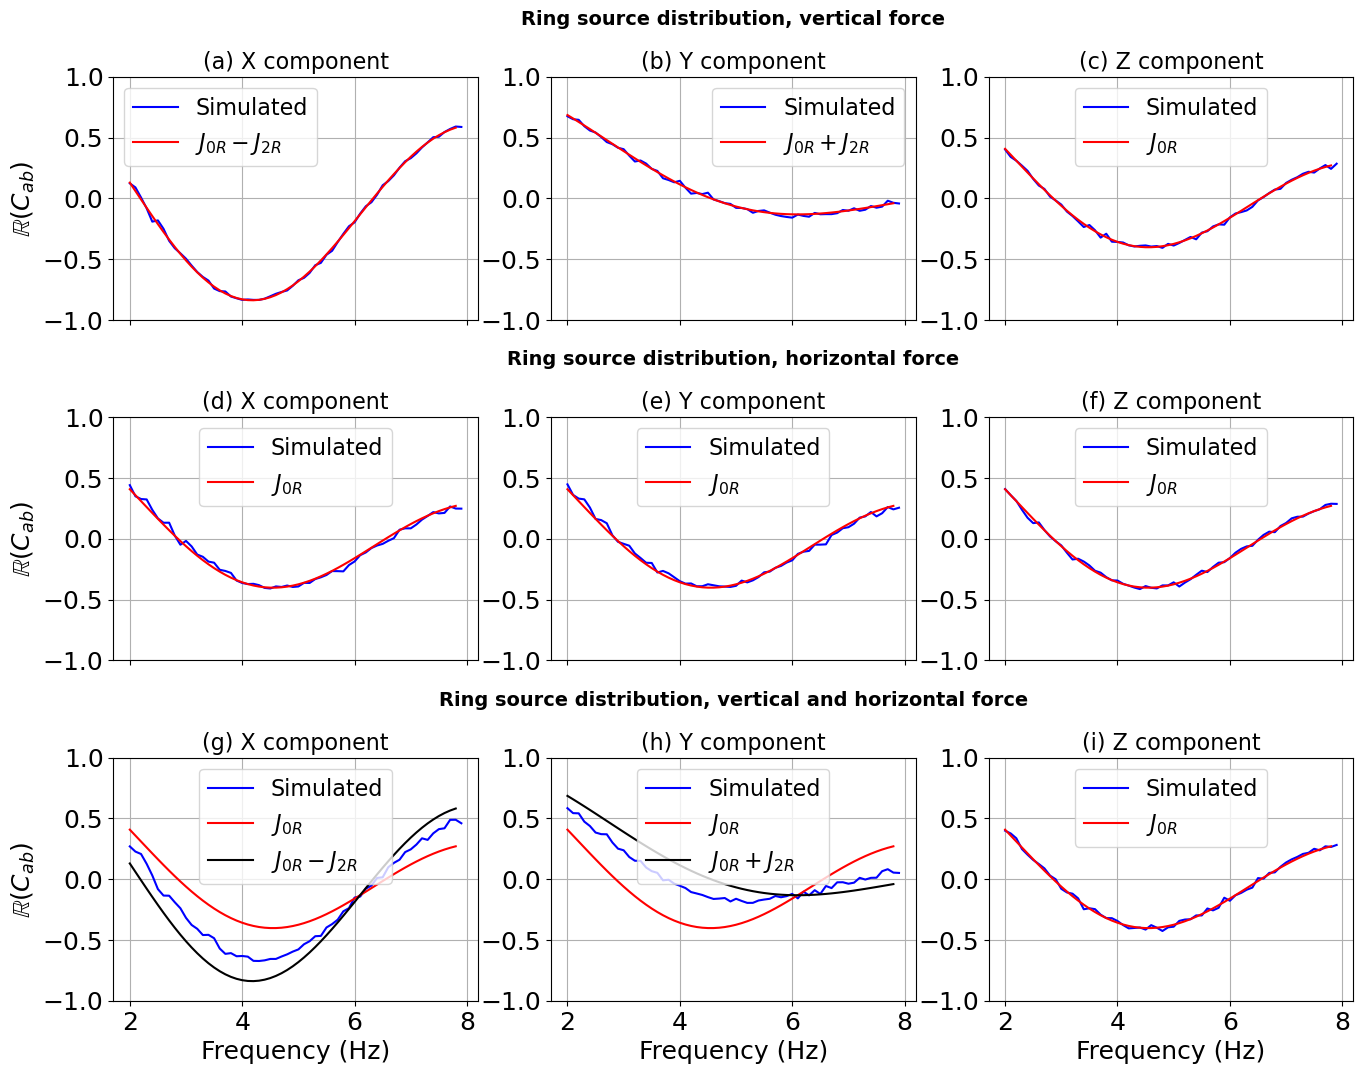

In [1]:
# script for plotting the simulated and theoretical cross-correlations and attenuatiuon
# for a homogeneous halfspace model
import numpy as np
import os
from joblib import Parallel, delayed
import matplotlib.pyplot as plt
from scipy.io import loadmat
from scipy.io import savemat
from scipy.special import j0
from scipy.special import spherical_jn
from scipy.special import jv
import scipy.constants as const

from modules import plotUtils

# state the filepaths
ccBigRingPathV = '/home/koley/Results/TutorialOut/HomoBigRingFullCCOut/OutDispRea/RingVCC.mat'
ccBigRingPathH = '/home/koley/Results/TutorialOut/HomoBigRingFullCCOut/OutDispRea/RingHCC.mat'
ccBigRingPathVH = '/home/koley/Results/TutorialOut/HomoBigRingFullCCOut/OutDispRea/RingVHCC.mat'

ccInternalPathV = '/home/koley/Results/TutorialOut/HomoInternalFullCCOut/OutDispRea/InternalVCC.mat'
ccInternalPathH = '/home/koley/Results/TutorialOut/HomoInternalFullCCOut/OutDispRea/InternalHCC.mat'
ccInternalPathVH = '/home/koley/Results/TutorialOut/HomoInternalFullCCOut/OutDispRea/InternalVHCC.mat'

figPath = '/home/koley/Results/FigPaper/CCHalfSpaceRingAllForce.pdf'
# use loadmat to load them
ccBRV = loadmat(ccBigRingPathV)
ccBRH = loadmat(ccBigRingPathH)
ccBRVH = loadmat(ccBigRingPathVH)

ccInV = loadmat(ccInternalPathV)
ccInH = loadmat(ccInternalPathH)
ccInVH = loadmat(ccInternalPathVH)

# load the plot style module
plotUtils.set_plot_style(labelsize=18, ticksize=18, legendsize=16)

# create the plot for vertical force only
fig,ax = plt.subplots(3,3,figsize = (16,12), sharex=True)
ax[0,0].plot(ccBRV["freqOut"][0],ccBRV["ccXRingV"][0],'b',label='Simulated')
ax[0,1].plot(ccBRV["freqOut"][0],ccBRV["ccYRingV"][0],'b',label='Simulated')
ax[0,2].plot(ccBRV["freqOut"][0],ccBRV["ccZRingV"][0],'b', label='Simulated')
# plot the theoretical ones
ax[0,0].plot(ccBRV["fTheo"][0],ccBRV["ccTheoJ0R"][0]-ccBRV["ccTheoJ2R"][0],'r',label=r'$J_{0R}-J_{2R}$')
ax[0,1].plot(ccBRV["fTheo"][0],ccBRV["ccTheoJ0R"][0]+ccBRV["ccTheoJ2R"][0],'r',label=r'$J_{0R}+J_{2R}$')
ax[0,2].plot(ccBRV["fTheo"][0],ccBRV["ccTheoJ0R"][0],'r',label=r'$J_{0R}$')
# set the labels, titles and grids
ax[0,0].set_ylabel(r"$\mathbb{R}(C_{ab})$")
titleStr = ["(a) X component","(b) Y component", "(c) Z component"]
for i in range(0,3):
    ax[0,i].set_title(titleStr[i])
    ax[0,i].grid()
    ax[0,i].set_ylim(-1,1)
    ax[0,i].legend()

# plots for the horizontal force only
ax[1,0].plot(ccBRH["freqOut"][0],ccBRH["ccXRingH"][0],'b',label='Simulated')
ax[1,1].plot(ccBRH["freqOut"][0],ccBRH["ccYRingH"][0],'b',label='Simulated')
ax[1,2].plot(ccBRH["freqOut"][0],ccBRH["ccZRingH"][0],'b', label='Simulated')
# plot the theoretical ones
ax[1,0].plot(ccBRH["fTheo"][0],ccBRH["ccTheoJ0R"][0],'r',label=r'$J_{0R}$')
ax[1,1].plot(ccBRH["fTheo"][0],ccBRH["ccTheoJ0R"][0],'r',label=r'$J_{0R}$')
ax[1,2].plot(ccBRH["fTheo"][0],ccBRH["ccTheoJ0R"][0],'r',label=r'$J_{0R}$')
ax[1,0].set_ylabel(r"$\mathbb{R}(C_{ab})$")
titleStr = ["(d) X component","(e) Y component", "(f) Z component"]
for i in range(0,3):
    ax[1,i].set_title(titleStr[i])
    ax[1,i].grid()
    ax[1,i].set_ylim(-1,1)
    ax[1,i].legend()

# plots for the vertical and horizontal force acting simulataneously
ax[2,0].plot(ccBRVH["freqOut"][0],ccBRVH["ccXRingVH"][0],'b',label='Simulated')
ax[2,1].plot(ccBRVH["freqOut"][0],ccBRVH["ccYRingVH"][0],'b',label='Simulated')
ax[2,2].plot(ccBRVH["freqOut"][0],ccBRVH["ccZRingVH"][0],'b', label='Simulated')
# plot the theoretical ones
ax[2,0].plot(ccBRVH["fTheo"][0],ccBRVH["ccTheoJ0R"][0],'r',label=r'$J_{0R}$')
ax[2,1].plot(ccBRVH["fTheo"][0],ccBRVH["ccTheoJ0R"][0],'r',label=r'$J_{0R}$')
ax[2,2].plot(ccBRVH["fTheo"][0],ccBRVH["ccTheoJ0R"][0],'r',label=r'$J_{0R}$')
ax[2,0].plot(ccBRV["fTheo"][0],ccBRV["ccTheoJ0R"][0]-ccBRV["ccTheoJ2R"][0],'k',label=r'$J_{0R}-J_{2R}$')
ax[2,1].plot(ccBRV["fTheo"][0],ccBRV["ccTheoJ0R"][0]+ccBRV["ccTheoJ2R"][0],'k',label=r'$J_{0R}+J_{2R}$')
ax[2,0].set_ylabel(r"$\mathbb{R}(C_{ab})$")
ax[2,0].set_xlabel("Frequency (Hz)")
ax[2,1].set_xlabel("Frequency (Hz)")
ax[2,2].set_xlabel("Frequency (Hz)")

titleStr = ["(g) X component","(h) Y component", "(i) Z component"]
for i in range(0,3):
    ax[2,i].set_title(titleStr[i])
    ax[2,i].grid()
    ax[2,i].set_ylim(-1,1)
    ax[2,i].legend()

# Leave space above each row title
fig.subplots_adjust(hspace=0.4)
row_titles = ["Ring source distribution, vertical force",
              "Ring source distribution, horizontal force",
              "Ring source distribution, vertical and horizontal force"]

# add the mini titles:
for i, title in enumerate(row_titles):
    # Get the position of the leftmost and rightmost axes in the row
    row_axes = ax[i, :]
    left = row_axes[0].get_position().x0
    right = row_axes[-1].get_position().x1
    top = row_axes[0].get_position().y1

    fig.text(
        (left + right) / 2,   # centered across the row
        top + 0.04,           # slightly above the row
        title,
        ha="center",
        va="bottom",
        fontsize=14,
        fontweight="bold"
    )

# save the figure
fig.savefig(figPath, bbox_inches="tight",transparent=False,metadata={"Creator": "Python/Matplotlib"})


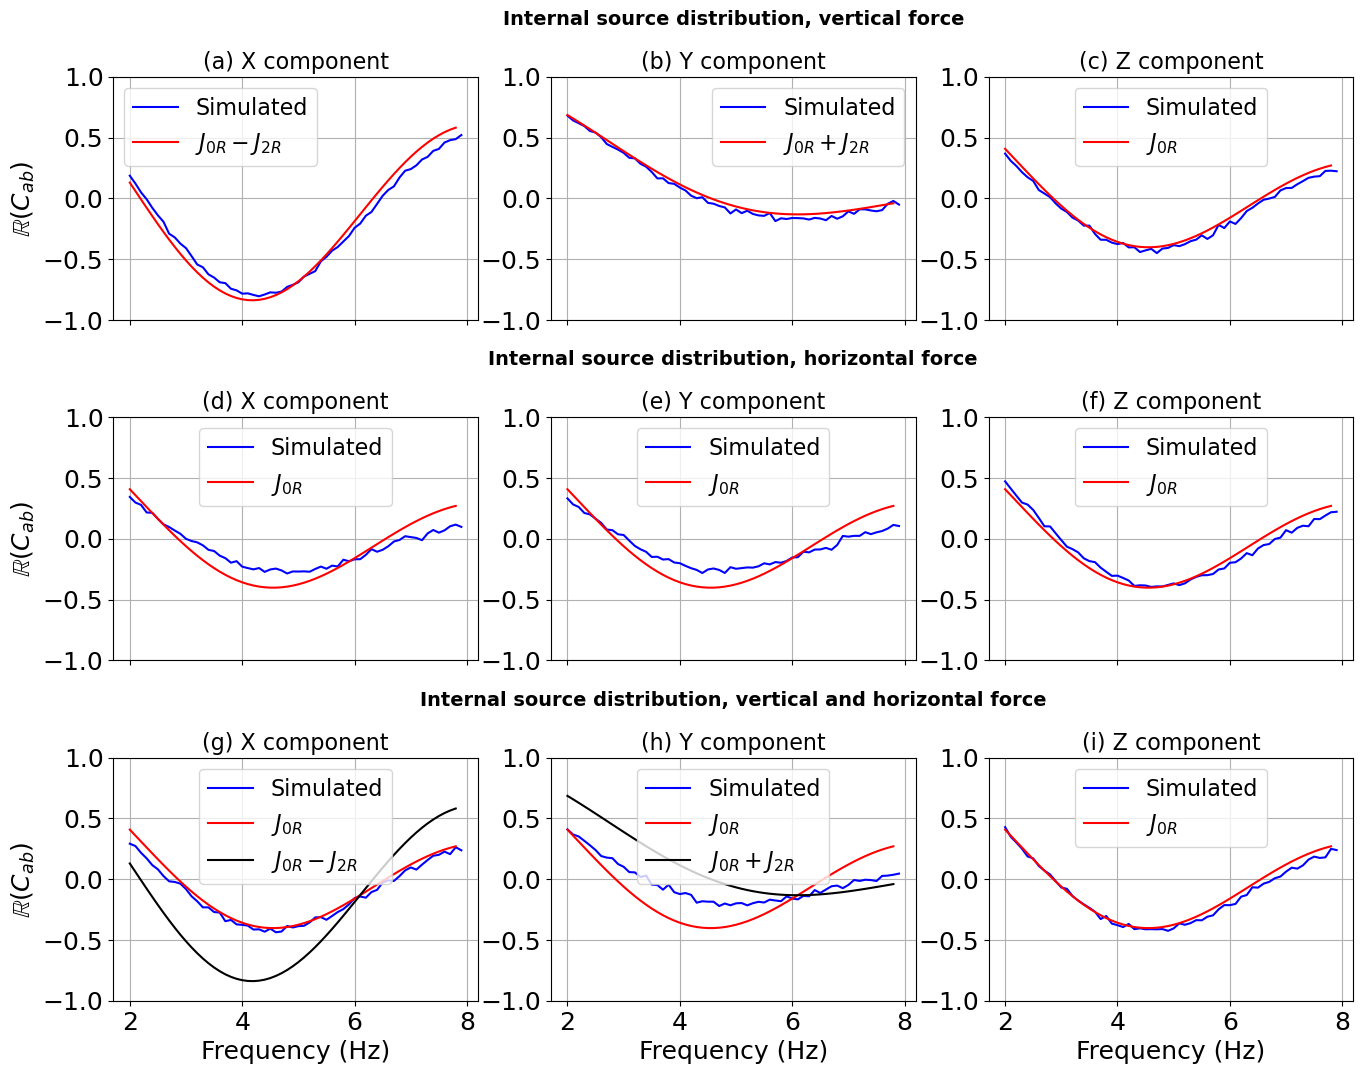

In [7]:
# no need to load modules if you run this after the first cell
ccInternalPathV = '/home/koley/Results/TutorialOut/HomoInternalFullCCOut/OutDispRea/InternalVCC.mat'
ccInternalPathH = '/home/koley/Results/TutorialOut/HomoInternalFullCCOut/OutDispRea/InternalHCC.mat'
ccInternalPathVH = '/home/koley/Results/TutorialOut/HomoInternalFullCCOut/OutDispRea/InternalVHCC.mat'

attnBigRingPath = '/home/koley/Results/TutorialOut/HomoBigRingFullAttnOut/OutDispRea/BigRingAttn.mat'
attnInternalPath = '/home/koley/Results/TutorialOut/HomoInternalFullAttnOut/OutDispRea/InternalAttn.mat'

figPath = '/home/koley/Results/FigPaper/CCHalfSpaceInternalAllForce.pdf'
# use loadmat to load them
ccInV = loadmat(ccInternalPathV)
ccInH = loadmat(ccInternalPathH)
ccInVH = loadmat(ccInternalPathVH)

# load the plot style module
plotUtils.set_plot_style(labelsize=18, ticksize=18, legendsize=16)
# do the case of internal source
# create the plot for vertical force only
fig,ax = plt.subplots(3,3,figsize = (16,12), sharex=True)
ax[0,0].plot(ccInV["freqOut"][0],ccInV["ccXInternalV"][0],'b',label='Simulated')
ax[0,1].plot(ccInV["freqOut"][0],ccInV["ccYInternalV"][0],'b',label='Simulated')
ax[0,2].plot(ccInV["freqOut"][0],ccInV["ccZInternalV"][0],'b', label='Simulated')
# plot the theoretical ones
ax[0,0].plot(ccBRV["fTheo"][0],ccBRV["ccTheoJ0R"][0]-ccBRV["ccTheoJ2R"][0],'r',label=r'$J_{0R}-J_{2R}$')
ax[0,1].plot(ccBRV["fTheo"][0],ccBRV["ccTheoJ0R"][0]+ccBRV["ccTheoJ2R"][0],'r',label=r'$J_{0R}+J_{2R}$')
ax[0,2].plot(ccBRV["fTheo"][0],ccBRV["ccTheoJ0R"][0],'r',label=r'$J_{0R}$')
# set the labels, titles and grids
ax[0,0].set_ylabel(r"$\mathbb{R}(C_{ab})$")
titleStr = ["(a) X component","(b) Y component", "(c) Z component"]
for i in range(0,3):
    ax[0,i].set_title(titleStr[i])
    ax[0,i].grid()
    ax[0,i].set_ylim(-1,1)
    ax[0,i].legend()

# plots for the horizontal force only
ax[1,0].plot(ccInH["freqOut"][0],ccInH["ccXInternalH"][0],'b',label='Simulated')
ax[1,1].plot(ccInH["freqOut"][0],ccInH["ccYInternalH"][0],'b',label='Simulated')
ax[1,2].plot(ccInH["freqOut"][0],ccInH["ccZInternalH"][0],'b', label='Simulated')
# plot the theoretical ones
ax[1,0].plot(ccInH["fTheo"][0],ccInH["ccTheoJ0R"][0],'r',label=r'$J_{0R}$')
ax[1,1].plot(ccInH["fTheo"][0],ccInH["ccTheoJ0R"][0],'r',label=r'$J_{0R}$')
ax[1,2].plot(ccInH["fTheo"][0],ccInH["ccTheoJ0R"][0],'r',label=r'$J_{0R}$')
ax[1,0].set_ylabel(r"$\mathbb{R}(C_{ab})$")
titleStr = ["(d) X component","(e) Y component", "(f) Z component"]
for i in range(0,3):
    ax[1,i].set_title(titleStr[i])
    ax[1,i].grid()
    ax[1,i].set_ylim(-1,1)
    ax[1,i].legend()

# plots for the vertical and horizontal force acting simulataneously
ax[2,0].plot(ccInVH["freqOut"][0],ccInVH["ccXInternalVH"][0],'b',label='Simulated')
ax[2,1].plot(ccInVH["freqOut"][0],ccInVH["ccYInternalVH"][0],'b',label='Simulated')
ax[2,2].plot(ccInVH["freqOut"][0],ccInVH["ccZInternalVH"][0],'b', label='Simulated')
# plot the theoretical ones
ax[2,0].plot(ccInVH["fTheo"][0],ccInVH["ccTheoJ0R"][0],'r',label=r'$J_{0R}$')
ax[2,1].plot(ccInVH["fTheo"][0],ccInVH["ccTheoJ0R"][0],'r',label=r'$J_{0R}$')
ax[2,2].plot(ccInVH["fTheo"][0],ccInVH["ccTheoJ0R"][0],'r',label=r'$J_{0R}$')
ax[2,0].plot(ccInV["fTheo"][0],ccInV["ccTheoJ0R"][0]-ccBRV["ccTheoJ2R"][0],'k',label=r'$J_{0R}-J_{2R}$')
ax[2,1].plot(ccInV["fTheo"][0],ccInV["ccTheoJ0R"][0]+ccBRV["ccTheoJ2R"][0],'k',label=r'$J_{0R}+J_{2R}$')
ax[2,0].set_ylabel(r"$\mathbb{R}(C_{ab})$")
ax[2,0].set_xlabel("Frequency (Hz)")
ax[2,1].set_xlabel("Frequency (Hz)")
ax[2,2].set_xlabel("Frequency (Hz)")

titleStr = ["(g) X component","(h) Y component", "(i) Z component"]
for i in range(0,3):
    ax[2,i].set_title(titleStr[i])
    ax[2,i].grid()
    ax[2,i].set_ylim(-1,1)
    ax[2,i].legend()

# Leave space above each row title
fig.subplots_adjust(hspace=0.4)
row_titles = ["Internal source distribution, vertical force",
              "Internal source distribution, horizontal force",
              "Internal source distribution, vertical and horizontal force"]

# add the mini titles:
for i, title in enumerate(row_titles):
    # Get the position of the leftmost and rightmost axes in the row
    row_axes = ax[i, :]
    left = row_axes[0].get_position().x0
    right = row_axes[-1].get_position().x1
    top = row_axes[0].get_position().y1

    fig.text(
        (left + right) / 2,   # centered across the row
        top + 0.04,           # slightly above the row
        title,
        ha="center",
        va="bottom",
        fontsize=14,
        fontweight="bold"
    )
    
fig.savefig(figPath, bbox_inches="tight",transparent=False,metadata={"Creator": "Python/Matplotlib"})

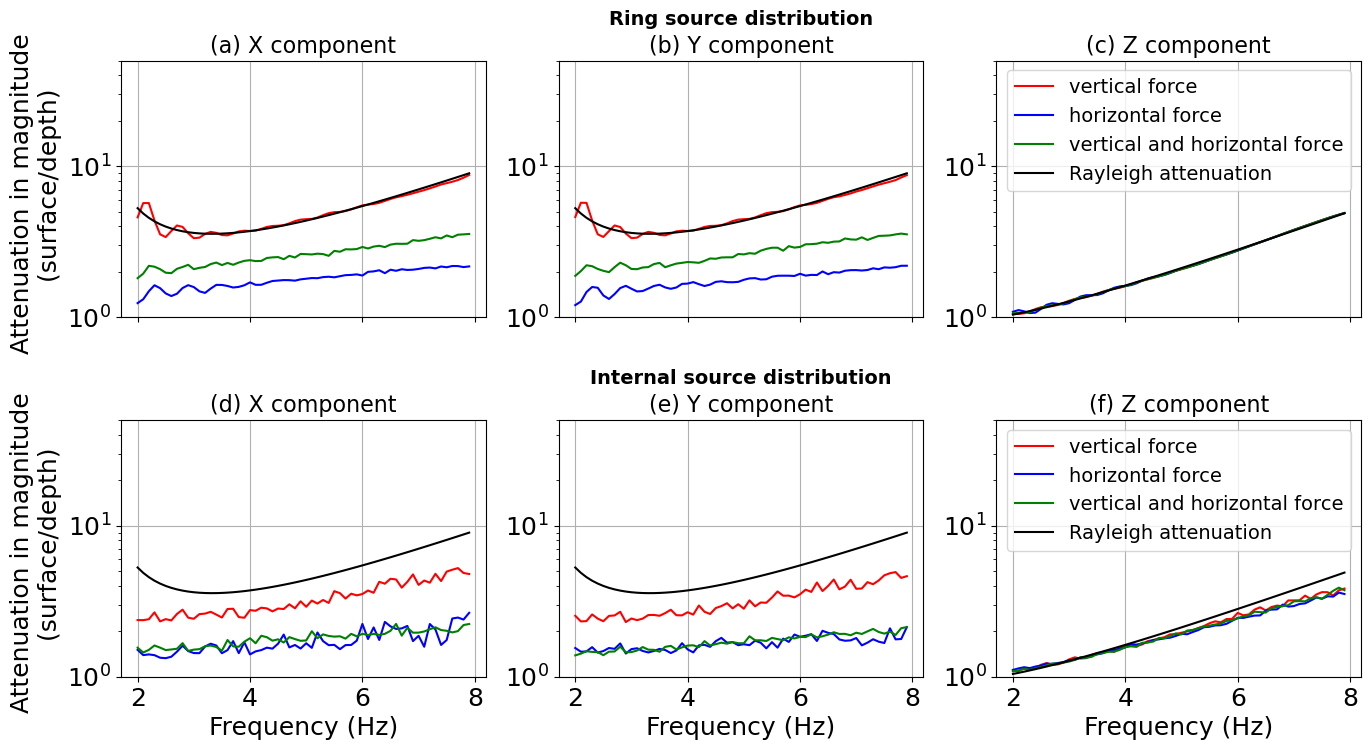

In [9]:
# plot the attenuation profiles

attnBigRingPathV = '/home/koley/Results/TutorialOut/HomoBigRingFullAttnOut/OutDispRea/BigRingAttnV.mat'
attnBigRingPathH = '/home/koley/Results/TutorialOut/HomoBigRingFullAttnOut/OutDispRea/BigRingAttnH.mat'
attnBigRingPathVH = '/home/koley/Results/TutorialOut/HomoBigRingFullAttnOut/OutDispRea/BigRingAttnVH.mat'

attnInternalPathV = '/home/koley/Results/TutorialOut/HomoInternalFullAttnOut/OutDispRea/InternalAttnV.mat'
attnInternalPathH = '/home/koley/Results/TutorialOut/HomoInternalFullAttnOut/OutDispRea/InternalAttnH.mat'
attnInternalPathVH = '/home/koley/Results/TutorialOut/HomoInternalFullAttnOut/OutDispRea/InternalAttnVH.mat'

figPath = '/home/koley/Results/FigPaper/attnHalfSpaceRingInternal.pdf'
attnBRV = loadmat(attnBigRingPathV)
attnBRH = loadmat(attnBigRingPathH)
attnBRVH = loadmat(attnBigRingPathVH)

attnInV = loadmat(attnInternalPathV)
attnInH = loadmat(attnInternalPathH)
attnInVH = loadmat(attnInternalPathVH)

# load the plot style module
plotUtils.set_plot_style(labelsize=18, ticksize=18, legendsize=16)
# do the case of ring source
# create the plot for vertical force only
fig,ax = plt.subplots(2,3,figsize = (16,8), sharex=True)

# plot the attenuation for the big ring distribution
# plot the X component
ax[0,0].plot(attnBRV["freqOut"][0],attnBRV["attnRingV"][:,0],'r',label='vertical force')
ax[0,0].plot(attnBRH["freqOut"][0],attnBRH["attnRingH"][:,0],'b',label='horizontal force')
ax[0,0].plot(attnBRVH["freqOut"][0],attnBRVH["attnRingVH"][:,0],'g', label='vertical and horizontal force')

# plot the Y component
ax[0,1].plot(attnBRV["freqOut"][0],attnBRV["attnRingV"][:,1],'r',label='vertical force')
ax[0,1].plot(attnBRH["freqOut"][0],attnBRH["attnRingH"][:,1],'b',label='horizontal force')
ax[0,1].plot(attnBRVH["freqOut"][0],attnBRVH["attnRingVH"][:,1],'g', label='vertical and horizontal force')

# plot the Z component
ax[0,2].plot(attnBRV["freqOut"][0],attnBRV["attnRingV"][:,2],'r',label='vertical force')
ax[0,2].plot(attnBRH["freqOut"][0],attnBRH["attnRingH"][:,2],'b',label='horizontal force')
ax[0,2].plot(attnBRVH["freqOut"][0],attnBRVH["attnRingVH"][:,2],'g', label='vertical and horizontal force')

# plot the theoretical ones
ax[0,0].plot(attnBRV["freqOut"][0],1/attnBRV["Th"][0],'k',label='Rayleigh attenuation')
ax[0,1].plot(attnBRV["freqOut"][0],1/attnBRV["Th"][0],'k',label='Rayleigh attenuation')
ax[0,2].plot(attnBRV["freqOut"][0],1/attnBRV["Tz"][0],'k',label='Rayleigh attenuation')

# plot the attenuation for the internal source distribution
# plot the X component
ax[1,0].plot(attnInV["freqOut"][0],attnInV["attnInternalV"][:,0],'r',label='vertical force')
ax[1,0].plot(attnInH["freqOut"][0],attnInH["attnInternalH"][:,0],'b',label='horizontal force')
ax[1,0].plot(attnInVH["freqOut"][0],attnInVH["attnInternalVH"][:,0],'g', label='vertical and horizontal force')

# plot the Y component
ax[1,1].plot(attnInV["freqOut"][0],attnInV["attnInternalV"][:,1],'r',label='vertical force')
ax[1,1].plot(attnInH["freqOut"][0],attnInH["attnInternalH"][:,1],'b',label='horizontal force')
ax[1,1].plot(attnInVH["freqOut"][0],attnInVH["attnInternalVH"][:,1],'g', label='vertical and horizontal force')

# plot the Z component
ax[1,2].plot(attnInV["freqOut"][0],attnInV["attnInternalV"][:,2],'r',label='vertical force')
ax[1,2].plot(attnInH["freqOut"][0],attnInH["attnInternalH"][:,2],'b',label='horizontal force')
ax[1,2].plot(attnInVH["freqOut"][0],attnInVH["attnInternalVH"][:,2],'g', label='vertical and horizontal force')

# plot the theoretical ones
ax[1,0].plot(attnInV["freqOut"][0],1/attnInV["Th"][0],'k',label='Rayleigh attenuation')
ax[1,1].plot(attnInV["freqOut"][0],1/attnInV["Th"][0],'k',label='Rayleigh attenuation')
ax[1,2].plot(attnInV["freqOut"][0],1/attnInV["Tz"][0],'k',label='Rayleigh attenuation')

# set the labels and legends
ax[0,0].set_ylabel(f"Attenuation in magnitude \n (surface/depth)")
ax[1,0].set_ylabel(f"Attenuation in magnitude \n (surface/depth)")
ax[1,0].set_xlabel("Frequency (Hz)")
ax[1,1].set_xlabel("Frequency (Hz)")
ax[1,2].set_xlabel("Frequency (Hz)")

titleStr = ["(a) X component","(b) Y component", "(c) Z component"]
for i in range(0,3):
    ax[0,i].set_title(titleStr[i])
    ax[0,i].grid()
    ax[0,i].set_yscale('log')
    ax[0,i].set_ylim(1,50)
    if(i==2):
        ax[0,i].legend(fontsize=14)

titleStr = ["(d) X component","(e) Y component", "(f) Z component"]
for i in range(0,3):
    ax[1,i].set_title(titleStr[i])
    ax[1,i].grid()
    ax[1,i].set_yscale('log')
    ax[1,i].set_ylim(1,50)
    if(i==2):
        ax[1,i].legend(fontsize=14)

# Leave space above each row title
fig.subplots_adjust(hspace=0.4)
row_titles = ["Ring source distribution",
              "Internal source distribution"]

# add the mini titles:
for i, title in enumerate(row_titles):
    # Get the position of the leftmost and rightmost axes in the row
    row_axes = ax[i, :]
    left = row_axes[0].get_position().x0
    right = row_axes[-1].get_position().x1
    top = row_axes[0].get_position().y1

    fig.text(
        (left + right) / 2,   # centered across the row
        top + 0.04,           # slightly above the row
        title,
        ha="center",
        va="bottom",
        fontsize=14,
        fontweight="bold"
    )

fig.savefig(figPath, bbox_inches="tight",transparent=False,metadata={"Creator": "Python/Matplotlib"})